# `ar_slotpos_digithead` on S7_k02345, seed 42 (notebook 35b)

This is the Transformer AR without pos(t) (op-slot embedding), own-token coordinates, with the output changed:
* **10-way digit head** (initialized from the original head's digit rows);
* **loss on the 36 answer digits only** (no EOS target);
* **36 decoding steps**; `<EOS>` is appended, not predicted.

No target coordinates: every output token keeps its OWN cell's (row, col), as in the ordinary AR.

| model | pos(t) | head / loss | target coords | notebook |
|---|---|---|---|---|
| original AR | yes | 20-way, 36 + EOS | no | 23b |
| `ar_digithead` | yes | **10-way, 36** | no | 35a |
| `ar_slotpos_digithead` | no | **10-way, 36** | no | 35b |
| `ar_slotpos_digithead_target` | no | 10-way, 36 | yes | 34 (singletons 1.00, k=6 1.00, k=7 0.985) |

**Questions.** 35a: does removing the EOS target alone fix the original AR? 35b vs 34: are target coordinates still
needed once the EOS target is gone?

Run 35a and 35b at the same time. The last cell (rerun after both finish) shows the full comparison table.
**Send back `AR_Ablation_S7_k02345_Review.ipynb`.**


In [1]:
# --- 2. Bootstrap: locate or clone the PRIVATE repository (credentials are never printed or stored) ---
import base64, importlib.util, os, pathlib, subprocess, sys

REPO_URL = "https://github.com/zhexuandliu/Decompositionality.git"
REPO_BRANCH = "main"
IN_COLAB = "google.colab" in sys.modules or "COLAB_RELEASE_TAG" in os.environ

def _find_repo():
    candidates = [pathlib.Path("/content/Decompositionality"), pathlib.Path.cwd(), *pathlib.Path.cwd().parents]
    for p in candidates:
        if (p / "src" / "decompositionality").is_dir():
            return p.resolve()
    return None

REPO_DIR = _find_repo()
if REPO_DIR is None:
    token = None
    if IN_COLAB:
        try:
            from google.colab import userdata
            token = userdata.get("GITHUB_TOKEN")
        except Exception:
            token = None
    if not token:
        import getpass
        token = getpass.getpass("GitHub token with read access to the private repo (input hidden): ")
    # Pass the credential through environment-scoped git config (not the URL, not the command line,
    # not persisted in .git/config).
    _hdr = "AUTHORIZATION: basic " + base64.b64encode(f"x-access-token:{token}".encode()).decode()
    _env = dict(os.environ, GIT_TERMINAL_PROMPT="0", GIT_CONFIG_COUNT="1",
                GIT_CONFIG_KEY_0="http.https://github.com/.extraheader", GIT_CONFIG_VALUE_0=_hdr)
    REPO_DIR = pathlib.Path("/content/Decompositionality" if IN_COLAB else "Decompositionality").resolve()
    _r = subprocess.run(["git", "clone", "--depth", "1", "--branch", REPO_BRANCH, REPO_URL, str(REPO_DIR)],
                        env=_env, capture_output=True, text=True)
    del token, _hdr, _env
    if _r.returncode != 0:
        raise RuntimeError("git clone failed (check the GITHUB_TOKEN secret / repo access):\n" + _r.stderr[-2000:])

if str(REPO_DIR / "src") not in sys.path:
    sys.path.insert(0, str(REPO_DIR / "src"))
for _mod in ("numpy", "pandas", "matplotlib", "torch"):
    if importlib.util.find_spec(_mod) is None:  # Colab already ships these; never reinstall torch/CUDA here
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", _mod], check=True)
REPO_COMMIT = subprocess.run(["git", "-C", str(REPO_DIR), "rev-parse", "HEAD"], capture_output=True, text=True).stdout.strip()
print("Repository:", REPO_DIR, "| commit:", REPO_COMMIT or "unknown")


Repository: /content/Decompositionality | commit: 950033e625202e35af3e30d1f2c96b970fd52e29


In [2]:
# --- CONFIGURATION -------------------------------------------------------------------------------------------------
MODE = os.environ.get("DECOMP_MODE", "full")
SEED = 42
RUN_CONDITIONS = ["S7_k02345"]
RUN_MODELS = ["ar_slotpos_digithead"]
STEPS = 20000
SUBDIR = "S7_support_sweep_20k_v1"                # same folder as notebooks 23 / 27 / 29 (model subfolders differ)
EVAL_PLAN = {"n_single_grids": 1000, "n_seen_per_k": 5000, "n_long_per_k": 20000}
USE_DRIVE = IN_COLAB
RESULTS_ROOT = os.environ.get("DECOMP_RESULTS_ROOT") or (
    "/content/drive/MyDrive/decompositionality_results" if USE_DRIVE else str(REPO_DIR / "results"))
DEVICE = os.environ.get("DECOMP_DEVICE", "auto")
# -----------------------------------------------------------------------------------------------------------------
if USE_DRIVE and IN_COLAB and RESULTS_ROOT.startswith("/content/drive"):
    from google.colab import drive
    drive.mount("/content/drive")
import pandas as pd
from IPython.display import display
pd.set_option("display.max_rows", 500); pd.set_option("display.max_columns", 60); pd.set_option("display.width", 250)
from decompositionality import longk as LK, longk_exp as LX, ar_ablation as AB
print("results ->", LX.family_root(RESULTS_ROOT, MODE, SUBDIR))


Mounted at /content/drive
results -> /content/drive/MyDrive/decompositionality_results/S7_support_sweep_20k_v1


In [3]:
# --- Train (20,000 updates) + sampled LAST-checkpoint evaluation (resumable) ---------------------------------------
status = LX.run_queue(RESULTS_ROOT, MODE, SEED, RUN_CONDITIONS, RUN_MODELS, repo_dir=str(REPO_DIR), device=DEVICE,
                      subdir=SUBDIR, steps=STEPS if MODE == "full" else None, sampled_plan=EVAL_PLAN)
display(status)


[S7_k02345] S=7 train k=[0, 2, 3, 4, 5] | val 1500 | manifests bdf24c327a65

=== S7_k02345 / ar_slotpos_digithead ===
  microbatch probe: 256 fits
[ar_slotpos_digithead] 10,670,218 params | device NVIDIA RTX PRO 6000 Blackwell Server Edition | dtype bf16 | microbatch 256 x accumulation 1 = 256
  [val @ 250] cell CE 1.6406 (best) | subset(160) exact 0.087 cell 0.353
  step 500/20000 loss 1.2871 lr 3.00e-04 | 24.02 steps/s, 6149 ex/s | ETA 13.5 min
  [val @ 500] cell CE 1.2777 (best) | subset(160) exact 0.212 cell 0.379
  [val @ 750] cell CE 1.0381 (best) | subset(160) exact 0.206 cell 0.405
  step 975/20000 loss 0.7959 lr 2.99e-04 | 23.56 steps/s, 6030 ex/s | ETA 13.5 min
  [val @ 1000] cell CE 0.8066 (best) | subset(160) exact 0.212 cell 0.461
  [val @ 1250] cell CE 0.5531 (best) | subset(160) exact 0.212 cell 0.555
  step 1450/20000 loss 0.3449 lr 2.98e-04 | 23.42 steps/s, 5995 ex/s | ETA 13.2 min
  [val @ 1500] cell CE 0.3303 (best) | subset(160) exact 0.325 cell 0.649
  [val @ 1750]

,condition,model,trained,evaluated_last,records,best_step (reference),complete
0,S7_k02345,ar_slotpos_digithead,True,True,82000,19750,True


# Transformer AR ablations on S7_k02345 (seed 42, LAST checkpoint, 20,000 updates)
Trained k = 0,2,3,4,5 in 7 slots; held out: singletons (k=1) at every slot, k=6, k=7. References: query AR (29b) and causal encoder (23b).


### Availability


,model,label,status
0,transformer_ar,original AR,ok
1,ar_slotpos,AR − pos(t),ok
2,ar_digiteos,AR + 11-way head (digits+EOS),ok
3,ar_slotpos_digiteos,AR − pos(t) + 11-way head,ok
4,ar_slotpos_digiteos_target,AR − pos(t) + 11-way head + target coords,ok
5,ar_digithead,AR + 10-way head (36 digits),ok
6,ar_slotpos_digithead,AR − pos(t) + 10-way head (36 digits),ok
7,ar_slotpos_digithead_target,AR − pos(t) + 10-way head (36 digits) + target...,ok
8,nexttoken_ar,"query AR, next-token feedback",no ARTIFACT
9,query_ar,query AR,ok



### 1. Exact accuracy by test k (k=1 = singletons over all slots)


model,k,role,original AR,AR − pos(t),AR + 11-way head (digits+EOS),AR − pos(t) + 11-way head,AR − pos(t) + 11-way head + target coords,AR + 10-way head (36 digits),AR − pos(t) + 10-way head (36 digits),AR − pos(t) + 10-way head (36 digits) + target coords,query AR,causal encoder
0,0,trained,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000
1,1,singleton,0.3305,0.0923,0.3491,0.3384,0.7526,0.5281,0.0000,1.0000,1.0000,1.0000
2,2,trained,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000
3,3,trained,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000
4,4,trained,1.0000,0.9998,1.0000,1.0000,0.9998,1.0000,1.0000,1.0000,1.0000,1.0000
5,5,trained,1.0000,0.9996,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000
6,6,+1 step,0.0136,0.0400,0.0023,0.2115,0.1163,0.0000,0.0000,0.9996,1.0000,0.9495
7,7,+2 step,0.0024,0.1121,0.0009,0.0048,0.1073,0.0000,0.3462,0.9848,0.9964,0.4642



### 2a. Singleton accuracy by operation


... (2 outputs left out)

model,op,slot,original AR,AR − pos(t),AR + 11-way head (digits+EOS),AR − pos(t) + 11-way head,AR − pos(t) + 11-way head + target coords,AR + 10-way head (36 digits),AR − pos(t) + 10-way head (36 digits),AR − pos(t) + 10-way head (36 digits) + target coords,query AR,causal encoder
0,A,1,0.000,0.601,0.000,0.000,0.144,0.000,0.0,1.0,1.0,1.0
1,A,2,0.000,0.106,0.000,0.000,0.230,0.058,0.0,1.0,1.0,1.0
2,A,3,0.000,0.165,0.000,0.000,0.628,0.048,0.0,1.0,1.0,1.0
3,A,4,0.000,0.029,0.000,0.000,0.990,1.000,0.0,1.0,1.0,1.0
4,A,5,0.000,0.025,0.000,0.015,0.908,0.994,0.0,1.0,1.0,1.0
5,A,6,0.000,0.000,0.051,0.042,0.808,0.995,0.0,1.0,1.0,1.0
6,A,7,0.000,0.000,1.000,0.846,0.088,0.997,0.0,1.0,1.0,1.0
7,B,1,0.958,0.094,0.301,1.000,1.000,0.999,0.0,1.0,1.0,1.0
8,B,2,0.984,0.094,0.993,1.000,1.000,1.000,0.0,1.0,1.0,1.0
9,B,3,0.999,0.094,1.000,1.000,1.000,1.000,0.0,1.0,1.0,1.0



### 3. k=6 failures that equal the word with ONE operation dropped (counts; 'drop #i' = i-th operation)


,model,k=6 records,failed,invalid outputs,drop #1,drop #2,drop #3,drop #4,drop #5,drop #6,drop some op / failed
0,original AR,20000,19729,0,1102,1003,1514,4310,12512,4404,0.634
1,AR − pos(t),20000,19201,4,1533,2500,4079,6374,3794,1621,0.484
2,AR + 11-way head (digits+EOS),20000,19954,0,966,931,1295,3576,9836,3909,0.493
3,AR − pos(t) + 11-way head,20000,15770,0,379,433,974,2217,3017,1752,0.198
4,AR − pos(t) + 11-way head + target coords,20000,17674,1,1180,2594,5357,4419,2299,1337,0.407
5,AR + 10-way head (36 digits),20000,20000,0,437,318,308,1110,3967,1981,0.198
6,AR − pos(t) + 10-way head (36 digits),20000,20000,0,2686,4534,5679,6141,4112,2372,0.638
7,AR − pos(t) + 10-way head (36 digits) + target...,20000,8,0,0,0,0,0,0,0,0.000
8,query AR,20000,1,0,0,0,0,0,0,0,0.000
9,causal encoder,20000,1010,0,0,0,0,0,0,0,0.000



### Accuracy vs test k


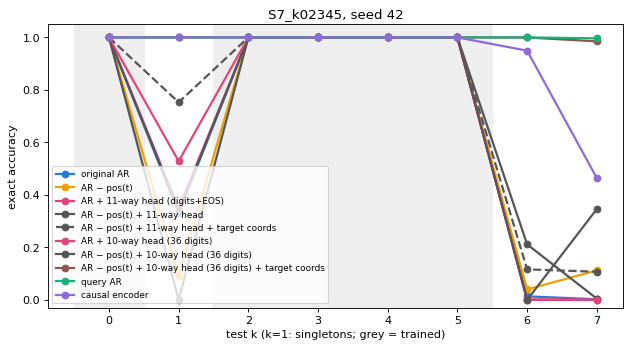

REVIEW FILE: /content/drive/MyDrive/decompositionality_results/S7_support_sweep_20k_v1/report/seed_42_ar_ablation/AR_Ablation_S7_k02345_Review.ipynb
REVIEW FILE TO SEND BACK: /content/drive/MyDrive/decompositionality_results/S7_support_sweep_20k_v1/report/seed_42_ar_ablation/AR_Ablation_S7_k02345_Review.ipynb


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [4]:
# --- Comparison (reads saved predictions only; rerun after all runs finish) ---------------------------------------
rp = AB.report(RESULTS_ROOT, MODE, SEED)
print("REVIEW FILE TO SEND BACK:", rp)
if IN_COLAB and rp:
    from google.colab import files
    files.download(str(rp))
